# EMQA_L5_fw_volume

**Romanian forward volume by product and year**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_fw_volume/EMQA_L5_fw_volume.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Volume of the Romanian forward market (OPCOM PCCB-LE-flex auctions) by year of the auction and delivery product.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
# OPCOM PCCB-LE-flex auction results: one row per traded session, price converted to EUR with the ECB EUR/RON fixing
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()


def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return 'other'
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return 'M'
    if n == 3 and s.month in (1, 4, 7, 10):
        return 'Q'
    if n == 6 and s.month in (1, 7):
        return 'H'
    if n == 12 and s.month == 1:
        return 'Y'
    return 'other'


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 +
                FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
# baseload ('banda LD') products with a standard delivery period
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()


def vwap(df):
    """Volume-weighted average price, EUR/MWh."""
    return float(np.average(df['price_eur_mwh'], weights=df['mwh'])) if len(df) else np.nan


def realised(s, e, col='RO'):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


print(len(FW), 'traded auctions from', d(FW['auction_date'].min()), 'to', d(FW['auction_date'].max()),
      '|', len(BASE), 'baseload auctions with a standard delivery period')

2298 traded auctions from 2020-05-12 to 2026-10-28 | 1361 baseload auctions with a standard delivery period


In [5]:
FW['year'] = FW['auction_date'].dt.year
vol = FW.pivot_table(index='year', columns='kind', values='mwh', aggfunc='sum').fillna(0) / 1e6   # TWh
for y in vol.index:
    show(f'TWh contracted in {y}' + (' (to the cut-off)' if y == END.year else ''), vol.loc[y].sum(), f'volume.{y}')
tot = FW['mwh'].sum()
sel = FW.groupby('seller')['mwh'].sum()
PROD3 = {'SOCIETATEA COMPLEXUL ENERGETIC OLTENIA S.A.': ('lignite (CE Oltenia)', 'who.sell_oltenia'),
         'SOCIETATEA NATIONALA NUCLEARELECTRICA S.A.': ('nuclear (Nuclearelectrica)', 'who.sell_snn'),
         'S.C. HIDROELECTRICA S.A.': ('hydro (Hidroelectrica)', 'who.sell_hidro')}
show('three state producers, % of the volume sold', 100 * sel.loc[list(PROD3)].sum() / tot, 'who.sell_top3_share', '.1f')
for s, (lab, key) in PROD3.items():
    show('  ' + lab + ', %', 100 * sel.loc[s] / tot, key, '.1f')
show('calendar-year products, % of baseload volume',
     100 * BASE.loc[BASE['kind'] == 'Y', 'mwh'].sum() / BASE['mwh'].sum(), 'volume.y_share_base', '.1f')

TWh contracted in 2020                                            15.42   [volume.2020]
TWh contracted in 2021                                            27.31   [volume.2021]
TWh contracted in 2022                                             7.44   [volume.2022]
TWh contracted in 2023                                             1.58   [volume.2023]
TWh contracted in 2024                                            17.53   [volume.2024]
TWh contracted in 2025                                             5.64   [volume.2025]
TWh contracted in 2026 (to the cut-off)                            8.76   [volume.2026]
three state producers, % of the volume sold                        83.1   [who.sell_top3_share]
  lignite (CE Oltenia), %                                          32.5   [who.sell_oltenia]
  nuclear (Nuclearelectrica), %                                    29.7   [who.sell_snn]
  hydro (Hidroelectrica), %                                        20.8   [who.sell_hidro]
calendar-year p

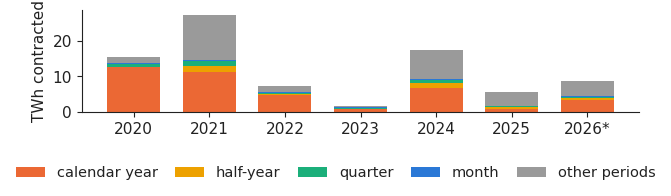

In [6]:
KCOL = {'M': PAL['RO'], 'Q': PAL['HU'], 'H': PAL['BG'], 'Y': PAL['DE_LU'], 'other': '#9a9a9a'}
KL = {'M': 'month', 'Q': 'quarter', 'H': 'half-year', 'Y': 'calendar year', 'other': 'other periods'}
fig, ax = plt.subplots(figsize=(6.4, 2.0))
bot = np.zeros(len(vol))
for k in ['Y', 'H', 'Q', 'M', 'other']:
    if k in vol:
        ax.bar(vol.index, vol[k].values, bottom=bot, color=KCOL[k], width=0.7, label=KL[k])
        bot += vol[k].values
ax.set_ylabel('TWh contracted')
ax.set_xticks(vol.index)
ax.set_xticklabels([str(y) + ('*' if y == END.year else '') for y in vol.index])   # * = to the cut-off
legend_bottom(fig, ncol=5)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('fw_volume.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()